# Atelier ML - Apprentissage: Parties 1 et 2
## But principal: choisir le bon Pokemon

**Probleme a resoudre:** apprendre le dresseur le bon Pokemon a utiliser lors d'un combat

Etapes du projet de Machine Learning:
1. Définition du problème à résoudre
2. Acquisition des données d’apprentissages et de tests
3. Préparer et nettoyer les données
4. Analyser, explorer les données
5. Choisir un modèle d’apprentissage
6. Visualiser les résultats, et ajuster ou modifier le modèle d’apprentissage

## Librairies utilisees: 

1. Numpy: Permet la manipulation de tableaux et matrices
2. Pandas: Permet la manipulation et l'analyse de donnees

In [162]:
import numpy as nmp
import pandas as pd

pd.set_option('display.max_columns', None) #Afficher toutes les colonnes
pd.set_option('future.no_silent_downcasting', True) #Supprimer les avertissements de downcasting

/tmp/ipykernel_3399/2650950320.py:5: Pandas4Warning: 'future.no_silent_downcasting' is deprecated, please refrain from using it.
  pd.set_option('future.no_silent_downcasting', True) #Supprimer les avertissements de downcasting


# 1. Preparation des donnees
## Les donnees du Pokedex

Les fichiers `pokedex.csv` et `combats.csv` sont situes dans le repertoire `data`.  On utilise `read_csv` pour charger le Pokedex dans un Dataframe.

In [163]:
nosPokemons = pd.read_csv("data/pokedex.csv")

# Affichage des colonnes du DataFrame
print(nosPokemons.columns.values)

<StringArray>
[                 'NUMERO',                     'NOM',
                  'TYPE_1',                  'TYPE_2',
           'POINTS_DE_VIE',          'NIVEAU_ATTAQUE',
          'NIVEAU_DEFENSE', 'NIVEAU_ATTAQUE_SPECIALE',
 'NIVEAU_DEFENSE_SPECIALE',                 'VITESSE',
      'NOMBRE_GENERATIONS',              'LEGENDAIRE']
Length: 12, dtype: str


| Colonne | Signification |
|---|---|
| NUMERO | Identifiant du Pokémon |
| NOM | Nom du Pokémon |
| TYPE_1 | Type primaire |
| TYPE_2 | Type secondaire |
| POINTS_DE_VIE | Points de vie |
| NIVEAU_ATTAQUE | Niveau d'attaque |
| NIVEAU_DEFENSE | Niveau de défense |
| NIVEAU_ATTAQUE_SPECIALE | Niveau d'attaque spéciale |
| NIVEAU_DEFENSE_SPECIALE | Niveau de défense spéciale |
| VITESSE | Vitesse |
| GENERATION | Génération du Pokémon |
| LEGENDAIRE | Pokémon légendaire (booléen) |

In [164]:
# Utilisation de Head du Dataframe pour afficher les dix premieres lignes

print(nosPokemons.head(10))

   NUMERO               NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1        Bulbizarre  Herbe  Poison             45              49   
1       2        Herbizarre  Herbe  Poison             60              62   
2       3        Florizarre  Herbe  Poison             80              82   
3       4   Mega Florizarre  Herbe  Poison             80             100   
4       5         Salameche    Feu     NaN             39              52   
5       6         Reptincel    Feu     NaN             58              64   
6       7         Dracaufeu    Feu     Vol             78              84   
7       8  Mega Dracaufeu X    Feu  Dragon             78             130   
8       9  Mega Dracaufeu Y    Feu     Vol             78             104   
9      10          Carapuce    Eau     NaN             44              48   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65     

Chaque ligne est une **observation** et chaque colonne une **feature**.

## Classement des features
- **Categorisation categorielle** : `TYPE_1`, `TYPE_2`, `LEGENDAIRE`
- **Categorisation numerique discrete** : `NUMERO`, `POINTS_DE_VIE`, `NIVEAU_ATTAQUE`, `NIVEAU_DEFENSE`, `NIVEAU_ATTAQUE_SPECIALE`, `NIVEAU_DEFENSE_SPECIALE`, `VITESSE`
- **Categorisation ordinale** : `GENERATION`

### Feature LEGENDAIRE
Le Machine Learning travaille seulement avec les donnees numeriques, donc "VRAI" et "FAUX" n'est pas exploitable. Il faudra alors transformer VRAI en 1 et FAUX en 0

In [165]:
# replacement de VRAI FAUX par 1 0 
nosPokemonsClean = nosPokemons
nosPokemonsClean['LEGENDAIRE'] = nosPokemonsClean['LEGENDAIRE'].replace("VRAI", 1)
nosPokemonsClean['LEGENDAIRE'] = nosPokemonsClean['LEGENDAIRE'].replace("FAUX", 0)
print(nosPokemonsClean.head())

   NUMERO              NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1       Bulbizarre  Herbe  Poison             45              49   
1       2       Herbizarre  Herbe  Poison             60              62   
2       3       Florizarre  Herbe  Poison             80              82   
3       4  Mega Florizarre  Herbe  Poison             80             100   
4       5        Salameche    Feu     NaN             39              52   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65       45   
1              63                       80                       80       60   
2              83                      100                      100       80   
3             123                      122                      120       80   
4              43                       60                       50       65   

   NOMBRE_GENERATIONS LEGENDAIRE  
0                   1      

### Manque-t-il des donnees ?
On compte les observations et les features avec `shape`, puis on cherche les valeurs absentes avec `info()`.

In [166]:
#Comptage du nombre d'observations et de features
print(nosPokemonsClean.shape)

(800, 12)


In [167]:
#Informations sur notre jeu de données
print(nosPokemonsClean.info())

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   NUMERO                   800 non-null    int64 
 1   NOM                      799 non-null    str   
 2   TYPE_1                   800 non-null    str   
 3   TYPE_2                   413 non-null    str   
 4   POINTS_DE_VIE            800 non-null    int64 
 5   NIVEAU_ATTAQUE           800 non-null    int64 
 6   NIVEAU_DEFENSE           800 non-null    int64 
 7   NIVEAU_ATTAQUE_SPECIALE  800 non-null    int64 
 8   NIVEAU_DEFENSE_SPECIALE  800 non-null    int64 
 9   VITESSE                  800 non-null    int64 
 10  NOMBRE_GENERATIONS       800 non-null    int64 
 11  LEGENDAIRE               800 non-null    object
dtypes: int64(8), object(1), str(3)
memory usage: 75.1+ KB
None


**Constats :**
- 800 observations et 12 features
- Il manque 1 `NOM` (799 sur 800)
- Il manque 387 `TYPE_2` (413 sur 800). C'est normal : un Pokemon peut ne pas avoir de type secondaire.

### Le nom manquant
On ne peut pas savoir si le nom a une incidence sur le résultat des combats, donc on ne laisse pas l'observation incomplete. On commence par la trouver.

In [168]:
print(nosPokemonsClean[nosPokemonsClean['NOM'].isnull()])

    NUMERO  NOM  TYPE_1 TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
62      63  NaN  Combat    NaN             65             105              60   

    NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
62                       60                       70       95   

    NOMBRE_GENERATIONS LEGENDAIRE  
62                   1          0  


Il s'agit de l'observation 62. Les Pokémons sont dans l'ordre du Pokedex national : on regarde le nom du precedent et du suivant, puis on cherche dans le Pokedex ([Pokepedia](https://www.pokepedia.fr/Liste_des_Pok%C3%A9mon_dans_l%27ordre_du_Pok%C3%A9dex_National)).

In [169]:
print(nosPokemonsClean['NOM'][61])
print(nosPokemonsClean['NOM'][63])

Ferosinge
Caninos


Le Pokemon entre Férosinge et Caninos est **Colossinge**. On renseigne la feature `NOM` de l'observation 62.

In [170]:
nosPokemonsClean.loc[62, 'NOM'] = "Colossinge"
print(nosPokemonsClean['NOM'][62])

Colossinge


Cette modification ne touche que le Dataframe, pas le fichier `pokedex.csv` d'origine.

## Les donnees des combats
On applique la meme demarche a `combats.csv` : chargement, features, dix premieres observations, comptage et recherche de donnees absentes.

In [171]:
#Chargement des données des combats
combats = pd.read_csv("data/combats.csv")

#Affichage des colonnes du Dataframe
print(combats.columns.values)

#Affichage des 10 premières lignes du Dataframe
print(combats.head(10))

#Comptage du nombre de lignes et de colonnes
print (combats.shape)

#Informations sur notre jeu de données
print (combats.info())

<StringArray>
['Premier_Pokemon', 'Second_Pokemon', 'Pokemon_Gagnant']
Length: 3, dtype: str
   Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
0              266             298              298
1              702             701              701
2              191             668              668
3              237             683              683
4              151             231              151
5              657             752              657
6              192             134              134
7               73             545              545
8              220             763              763
9              302              31               31
(50000, 3)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Premier_Pokemon  50000 non-null  int64
 1   Second_Pokemon   50000 non-null  int64
 2   Pokemon_Gagnant  50000 non-null  int64
dtypes:

**Constats :**
- 50 000 observations et 3 features : `Premier_Pokemon`, `Second_Pokemon`, `Pokemon_Gagnant`.
- `Pokemon_Gagnant` contient le numero du Pokemon gagnant
- Chaque feature est de type numerique
- Il ne manque aucune information

## Assemblage des observations
Il faut reunir les informations des combats et des caracteristiques des Pokemons afin de savoir pour chaque Pokemon le nombre de combats menes ainsi que le nombre de victoires

### Nombre de combats menes
Lors d’un combat, le Pokémon peut être utilisé en première position ou en seconde position. Cette position à une importance car elle permet de savoir qui va donner le premier coup. Dans le cas où notre pokemon à peu de points de vie, s’il joue en seconde position, on risque de perdre avant de donner notre premier coup

| Combat | Premier Pokemon | Second Pokemon |
|---|---|---|
| 1 | Bulbizarre | Dracaufeu |
| 2 | Dracaufeu | Colossinge |
| 3 | Dracaufeu | Pikachu |

Donnant alors le nombre de combats par Pokémon :

| Pokemon | Nombre de combats |
|---|---|
| Bulbizarre | 1 |
| Dracaufeu | 3 |
| Colossinge | 1 |
| Pikachu | 1 |

In [172]:
nbFoisPremierePosition = combats.groupby('Premier_Pokemon').count() # Comptage du nombre de fois où chaque Pokémon apparaît en première position
print(nbFoisPremierePosition) 

                 Second_Pokemon  Pokemon_Gagnant
Premier_Pokemon                                 
1                            70               70
2                            55               55
3                            68               68
4                            62               62
5                            50               50
...                         ...              ...
796                          49               49
797                          64               64
798                          60               60
799                          75               75
800                          61               61

[784 rows x 2 columns]


Si l’on reprend notre exemple, les données que nous obtenons seraient :
| Pokemon | Nombre PREMIERE_POSITION |
|---|---|
| Bulbizarre | 1 |
| Dracaufeu | 2 |
| Colossinge | 0 |
| Pikachu | 0 |

Il s’agit donc de compter le nombre de fois où le Pokémon est en première position via l’instruction `count()` puis de regrouper le résultat via l’instruction `groupBy()`

In [173]:
nbFoisSecondePosition = combats.groupby('Second_Pokemon').count()
print(nbFoisSecondePosition)

nombreTotalDeCombats = nbFoisPremierePosition + nbFoisSecondePosition
print(nombreTotalDeCombats)

                Premier_Pokemon  Pokemon_Gagnant
Second_Pokemon                                  
1                            63               63
2                            66               66
3                            64               64
4                            63               63
5                            62               62
...                         ...              ...
796                          56               56
797                          67               67
798                          59               59
799                          69               69
800                          60               60

[784 rows x 2 columns]
                 Pokemon_Gagnant  Premier_Pokemon  Second_Pokemon
Premier_Pokemon                                                  
1                            133              NaN             NaN
2                            121              NaN             NaN
3                            132              NaN             NaN
4        

### Nombre de combats gagnés

In [174]:
nombreDeVictoires = combats.groupby('Pokemon_Gagnant').count()
print(nombreDeVictoires)

                 Premier_Pokemon  Second_Pokemon
Pokemon_Gagnant                                 
1                             37              37
2                             46              46
3                             89              89
4                             70              70
5                             55              55
...                          ...             ...
796                           39              39
797                          116             116
798                           60              60
799                           89              89
800                           75              75

[783 rows x 2 columns]


En agrégeant les deux tableaux que nous venons de constituer, on constate que le Pokémon 228 a gagné 104 combats, alors qu’il en a mené 150 (cf. tableau précédent) alors que les quatre premiers Pokémons ont gagné tous leurs combats

En utilisant la fonction `info()`, nous constatons que nous disposons que de 783 observations. Cela signifie qu’il existe des Pokémons n’ayant jamais gagné ! Charge à présent de les découvrir

In [175]:
jamaisGagne = nosPokemonsClean[~nosPokemonsClean['NUMERO'].isin(nombreDeVictoires.index)]
print(len(jamaisGagne), "Pokémons n'ont jamais gagné :")
print(jamaisGagne[['NUMERO', 'NOM', 'TYPE_1', 'POINTS_DE_VIE', 'NIVEAU_ATTAQUE', 'VITESSE']])

17 Pokémons n'ont jamais gagné :
     NUMERO                       NOM      TYPE_1  POINTS_DE_VIE  \
11       12                   Tortank         Eau             79   
32       33                 Sabelette         Sol             50   
45       46                 Grodoudou      Normal            140   
65       66                   Ptitard         Eau             40   
77       78                  Empiflor       Herbe             80   
89       90                  Magneton  Electrique             50   
143     144                 Metamorph      Normal             48   
182     183                   Migalos     Insecte             70   
230     231                  Caratroc     Insecte             20   
235     236                  Ursaring      Normal             90   
321     322                  Hariyama      Combat            144   
418     419               Mega Latias      Dragon             80   
478     479                   Corboss      Obscur            100   
555     556    

### Agrégation des données avec le Pokédex
On crée d'abord une liste contenant, pour chaque numéro de Pokémon : le nombre de combats, le nombre de victoires et le pourcentage de victoires. Le numéro sert de clé d'agrégation avec le Pokédex.

In [176]:
listeAAgreger = combats.groupby('Pokemon_Gagnant').count()
listeAAgreger.sort_index()

#On ajoute le nombre de combats
listeAAgreger['NBR_COMBATS'] = nbFoisPremierePosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant

#On ajoute le nombre de victoires
listeAAgreger['NBR_VICTOIRES'] = nombreDeVictoires.Premier_Pokemon

#On calcule le pourcentage de victoires
listeAAgreger['POURCENTAGE_DE_VICTOIRES'] = nombreDeVictoires.Premier_Pokemon / (nbFoisPremierePosition.Pokemon_Gagnant + nbFoisSecondePosition.Pokemon_Gagnant)

#On affiche la nouvelle liste
print(listeAAgreger)

                 Premier_Pokemon  Second_Pokemon  NBR_COMBATS  NBR_VICTOIRES  \
Pokemon_Gagnant                                                                
1                             37              37          133             37   
2                             46              46          121             46   
3                             89              89          132             89   
4                             70              70          125             70   
5                             55              55          112             55   
...                          ...             ...          ...            ...   
796                           39              39          105             39   
797                          116             116          131            116   
798                           60              60          119             60   
799                           89              89          144             89   
800                           75        

On fusionne avec le Pokédex grâce à `merge()`, en utilisant l'index de la liste (`right_index=True`) lié à la feature `NUMERO` (`how='left'` conserve les 800 Pokémons, y compris ceux qui n'ont jamais gagné).

In [177]:
nouveauPokedex = nosPokemonsClean.merge(listeAAgreger, left_on='NUMERO', right_index = True, how='left')
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

# 2. Analyses statistiques

## Un peu de statistiques
Avant d’entrer dans le vif du sujet, nous allons faire un peu de statistiques sur notre jeu d’observations à l’aide de la fonction `describe()` du module Pandas.

In [178]:
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

À titre d’exemple, prenons le résultat de l’analyse statistique de la feature `NIVEAU_ATTAQUE`:
- **count** = 800: aucune donnee manquante
- **mean** (moyenne) = 79: on peut considerer qu'en dessous de cette moyenne, le Pokemon a un niveau faible, et au-dessus, il a un niveau fort. Premiere information interessantes
- **std** (ecart-type) = 32:  les données de la feature `NIVEAU_ATTAQUE` semblent être assez éloignées de la moyenne. Cela signifie qu’il existe de nombreux cas différents de niveaux d’attaque et que les observations ne sont pas homogènes. C’est un point que nous devrons vérifier lors de la visualisation des données
- **min = 5, max = 190** : de très faibles à très forts niveaux d'attaque.
- **Quartiles** : 25 % des Pokémons ont une attaque inférieure à 55, 50 % inférieure à 75, 75 % inférieure à 100. Peu de Pokémons (25 %) dépassent 100

### Description du jeu d'observations
- Les résultats des combats reposent sur des données numériques (VITESSE, NIVEAU_ATTAQUE...) : on peut exclure `NOM`, `TYPE_1`, `TYPE_2` de cette analyse
- Le `NUMERO` est un identifiant : il n'a pas de lien avec le fait de gagner un combat
- Certains Pokémons n'ont qu'un seul point de vie : à éviter
- 25 % des Pokémons ont une vitesse supérieure à 90 : être rapide peut être un avantage
- L'écart type du nombre de combats est le plus bas (environ 11, pour une moyenne proche de 127) : tous les Pokémons ont combattu à peu près autant. Le jeu de données est donc de bonne qualité pour l'apprentissage

## Quels types de Pokémons un dresseur doit-il posséder ?
Les types les plus fréquents sont ceux que les adversaires ont le plus de chances de posséder. On visualise le nombre de Pokémons par type avec un `countplot`.
On note l’import du module matplotlib, et l’utilisation du module seaborn, tous deux nécessaires à la représentation graphique des données

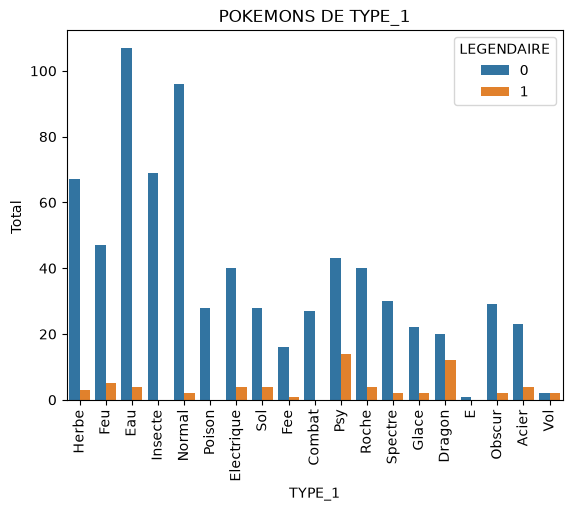

In [179]:
import matplotlib.pyplot as plt
import seaborn as sns

axe_X = sns.countplot(x="TYPE_1", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_1')
plt.ylabel('Total ')
plt.title("POKEMONS DE TYPE_1")
plt.show()

In [ ]:
axe_X = sns.countplot(x="TYPE_2", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation= 90)
plt.xlabel('TYPE_2')
plt.ylabel('Total ')
plt.title("POKEMONS DE TYPE_2")
plt.show()